# Figure 1
Run all cells to regenerate Figure 1 from saved results; no model fitting is performed.

Panels a–g use the original six matrices and autocorrelations. Panels h–i use 100 subjects and the exact 50-point tau grid from 0.354813 to 100 TR. The green curve compares each subject's EC with its own EC at the common group tau*, chosen at the red-mean minimum in the range with at least 70% eligible subjects. Initial outliers are circled. Asymmetry is the original sum(abs(J−J.T))/(2 sum(abs(J))), including the diagonal. The right-hand axis shows the correlation between antisymmetric J and Q1.

Inputs are the saved NPZ files, local Schaefer atlas and Avenir font. Output: `Figures/figure_1_preview_100subjects/figure_1_100subjects.jpg`.


In [2]:
from pathlib import Path
import numpy as np
import nibabel as nib
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm

PROJECT = Path.home() / 'Scripts/Insight_project'
NUMPY = PROJECT / 'numpy files'
FIGURES = PROJECT / 'Figures'
F1_OUTPUT = FIGURES / 'figure_1_preview_100subjects'
F1_OUTPUT.mkdir(parents=True, exist_ok=True)
font_file = PROJECT / 'Notebook figure/Avenir-Oblique.ttf'
fm.fontManager.addfont(font_file)
plt.rcParams['font.family'] = fm.FontProperties(fname=font_file).get_name()

def dediag(matrix):
    matrix = np.array(matrix, copy=True)
    np.fill_diagonal(matrix, 0)
    return matrix


In [3]:
with np.load(NUMPY / 'figure_1_recomputed_20260929.npz', allow_pickle=False) as saved:
    js = saved['js'].copy()
    cc = saved['cc'].copy()
    tau_obj = float(saved['tau_obj'])
    tau_obj_ = float(saved['tau_obj_'])
    matrix_taus = saved['taus'].copy()
assert js.shape == (6, 62, 62)
np.testing.assert_allclose(matrix_taus, [0.4, 0.6, 0.8, 5, tau_obj_, tau_obj])
np.testing.assert_allclose(-1 / np.diagonal(js, axis1=1, axis2=2), np.broadcast_to(matrix_taus[:, None], (6,62)))
label_table = nib.load(PROJECT / 'Schaefer2018_100Parcels_7Networks_order.dlabel.nii').header.get_axis(0).label[0]
labels100 = np.array([label_table[i][0].removeprefix('7Networks_') for i in range(1, 101)])


In [4]:
F1_SHOW_ASYM_CORRELATION = True
with np.load(F1_OUTPUT / 'panel_hi_metrics.npz', allow_pickle=False) as saved:
    f1_subjects = saved['subject_ids'].copy()
    f1_taus = saved['taus'].copy()
    f1_precision = saved['corr_precision'].copy()
    f1_similarity = saved['corr_EC_reference'].copy()
    f1_asymmetry = saved['asymmetry'].copy()
    f1_asymcorr = saved['corr_asymJ_asymQ1'].copy()
    f1_search = saved['search_mask'].copy()
    f1_excluded = saved['excluded_initial'].copy()
    f1_red_outliers = saved['red_outliers'].copy()
    f1_group_index = int(saved['group_reference_index'])
    f1_group_tau = float(saved['group_reference_tau'])
F1_N_SUBJECTS = len(f1_subjects)
assert F1_N_SUBJECTS == 100
assert all(a.shape == (100,50) for a in [f1_precision,f1_similarity,f1_asymmetry,f1_asymcorr,f1_search])
np.testing.assert_allclose(f1_taus, np.logspace(-0.45, 2, 50))
assert np.isclose(f1_group_tau, f1_taus[f1_group_index])
np.testing.assert_allclose(f1_similarity[:,f1_group_index], 1)

def f1_mean_complete(values):
    valid = np.isfinite(values).all(axis=0)
    mean = np.full(values.shape[1], np.nan)
    mean[valid] = values[:,valid].mean(axis=0)
    return mean

f1_mean_precision = f1_mean_complete(np.where(f1_red_outliers | f1_excluded, np.nan, f1_precision))
f1_mean_similarity = f1_mean_complete(np.where(f1_excluded, np.nan, f1_similarity))
f1_mean_asymmetry = f1_mean_complete(np.where(f1_excluded, np.nan, f1_asymmetry))
f1_mean_asymcorr = f1_mean_complete(np.where(f1_excluded, np.nan, f1_asymcorr))
f1_shade = f1_search.mean(axis=0) >= 0.7
f1_shade_left, f1_shade_right = f1_taus[f1_shade].min(), f1_taus[f1_shade].max()
candidates = np.flatnonzero(f1_shade & np.isfinite(f1_mean_precision))
assert f1_group_index == candidates[np.argmin(f1_mean_precision[candidates])]
print(f'Subjects: {F1_N_SUBJECTS}; group tau*: {f1_group_tau:.6f} TR')


Subjects: 100; group tau*: 0.891251 TR


Mapping: (100,) range = 1 - 62
Saved preview: /home/benedetta/Scripts/Insight_project/Figures/figure_1_preview_100subjects/figure_1_100subjects.jpg


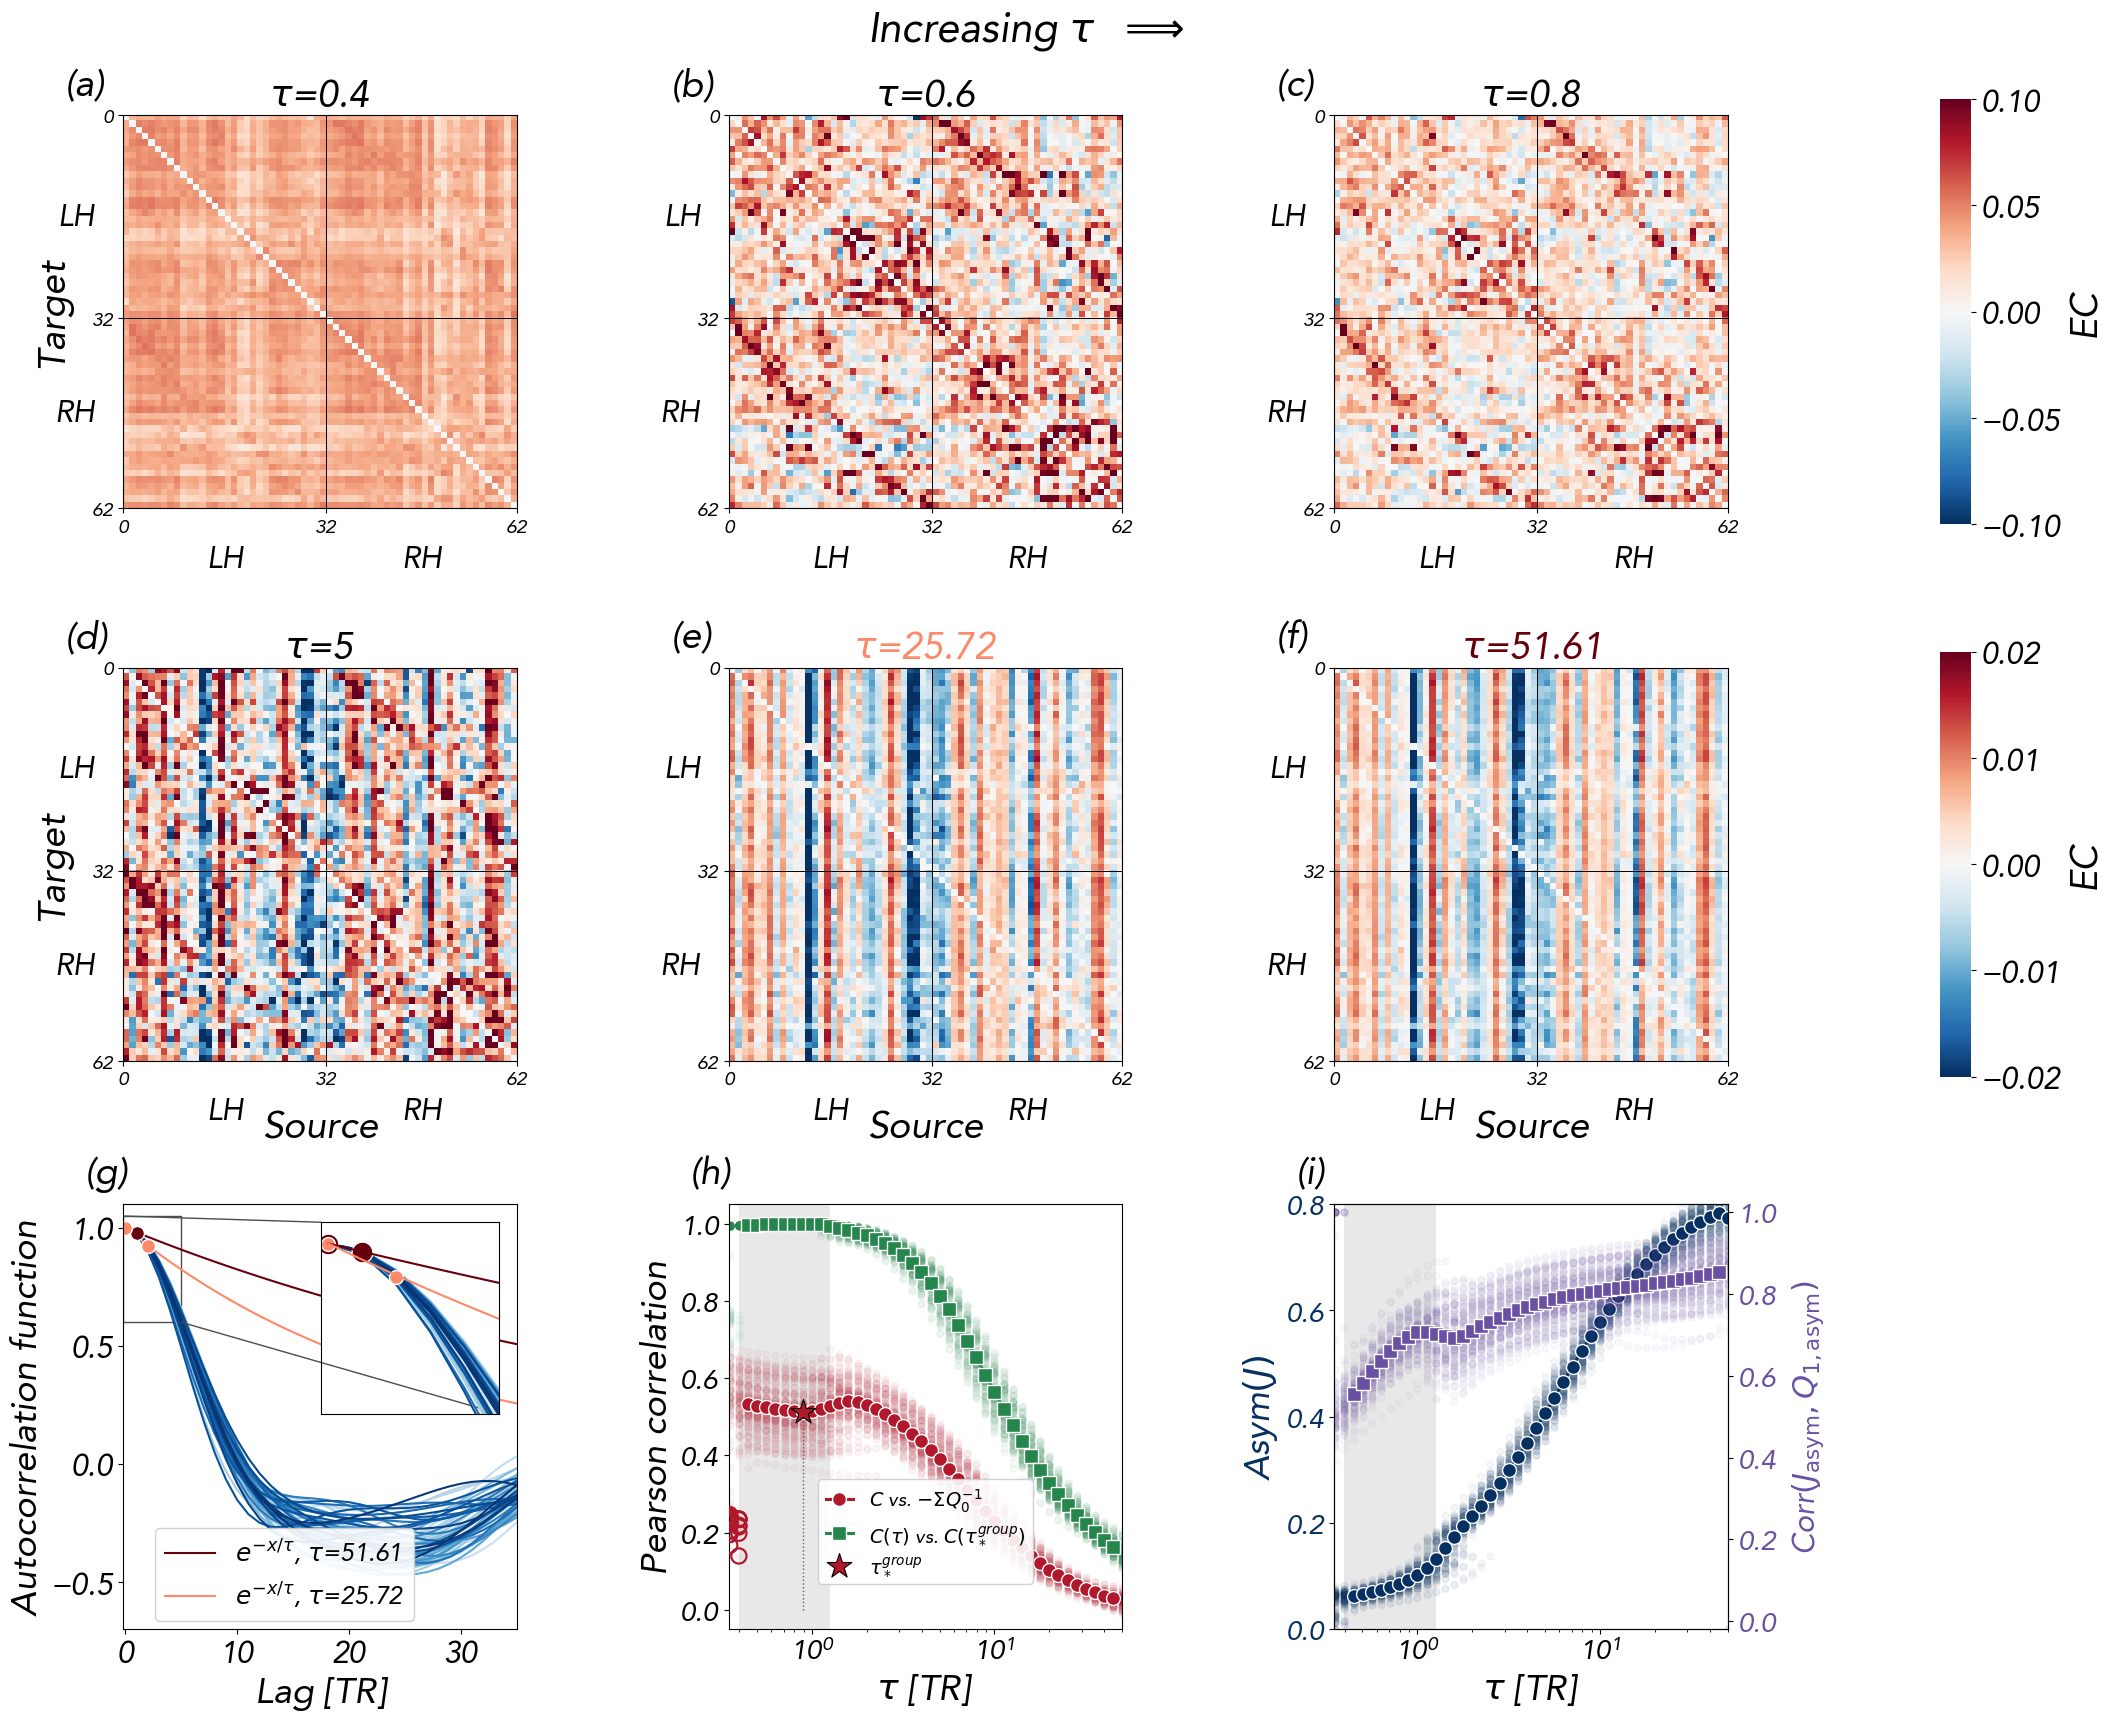

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset
from collections import OrderedDict
plt.rcParams['font.size'] = 26
plt.rcParams['xtick.labelsize'] = 22
plt.rcParams['ytick.labelsize'] = 22
fontsize = 27
cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))
asym_color = colors[0]
directionality_color = cm.Purples(0.75)
from collections import Counter
mapping_100_to_62 = np.array([1, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 4, 5, 5, 6, 7, 8, 7, 8, 7, 9, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 24, 25, 24, 26, 27, 28, 29, 28, 30, 31, 32, 32, 33, 34, 34, 34, 35, 35, 34, 35, 36, 36, 36, 37, 38, 38, 38, 38, 39, 40, 41, 41, 42, 43, 43, 44, 45, 46, 47, 47, 48, 49, 50, 51, 52, 52, 53, 52, 54, 55, 54, 56, 57, 58, 58, 59, 59, 60, 60, 61, 62, 62])
print('Mapping:', mapping_100_to_62.shape, 'range =', mapping_100_to_62.min(), '-', mapping_100_to_62.max())

def aggregate_labels(labels_100, mapping=mapping_100_to_62):
    labels_100 = np.asarray(labels_100)
    labels_62 = []
    for k in range(1, 63):
        idx = np.where(mapping == k)[0]
        labs = labels_100[idx]
        hemis = [str(x).split('_')[0] for x in labs]
        nets = [str(x).split('_')[1] for x in labs]
        hemi = Counter(hemis).most_common(1)[0][0]
        net = Counter(nets).most_common(1)[0][0]
        labels_62.append(f'{hemi}_{net}_{k}')
    return np.array(labels_62)

def plot_fc_matrix(fc, labels, ax, cmap='bwr', vmin=-0.2, vmax=0.2, fontsize=14, pos=7, plot_networks=False, plot_emi_x=True, plot_emi_y=True):
    fc = np.asarray(fc)
    labels = np.asarray(labels)
    if fc.ndim != 2 or fc.shape[0] != fc.shape[1]:
        raise ValueError('La matrice deve essere quadrata.')
    if labels.ndim != 1 or len(labels) != fc.shape[0] or len(labels) == 0:
        raise ValueError('Serve una etichetta per ogni regione.')
    if any((len(str(lab).split('_')) < 2 or str(lab).split('_')[0] not in ('LH', 'RH') for lab in labels)):
        raise ValueError('Etichette attese: LH_rete_regione oppure RH_rete_regione.')

    def parse_label(lab):
        p = str(lab).split('_')
        return (p[0], p[1])
    groups = OrderedDict()
    for (i, lab) in enumerate(labels):
        (hemi, net) = parse_label(lab)
        groups.setdefault(f'{hemi}_{net}', []).append(i)
    new_order = []
    bounds = []
    names = []
    start = 0
    ordered_keys = [key for hemi in ('LH', 'RH') for key in groups if key.startswith(hemi + '_')]
    for key in ordered_keys:
        idxs = groups[key]
        new_order.extend(idxs)
        end = start + len(idxs)
        bounds.append((start, end))
        names.append(key)
        start = end
    fc_ord = fc[np.ix_(new_order, new_order)]
    labels_ord = labels[new_order]
    n = len(labels_ord)
    im = ax.imshow(fc_ord, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='none', origin='upper')
    if plot_networks:
        for (start, end) in bounds:
            ax.axhline(end - 0.5, color='black', lw=0.2)
            ax.axvline(end - 0.5, color='black', lw=0.2)
        for ((start, end), name) in zip(bounds, names):
            center = (start + end) / 2 - 0.5
            net = name.split('_', 1)[1]
            ax.text(center, n + 1, net, ha='center', va='top', rotation=70, fontsize=fontsize, clip_on=False)
            ax.text(-1, center, net, ha='right', va='center', fontsize=fontsize, clip_on=False)
    lh_count = np.sum([str(x).startswith('LH_') for x in labels_ord])
    if 0 < lh_count < n:
        ax.axhline(lh_count - 0.5, color='black', lw=0.7)
        ax.axvline(lh_count - 0.5, color='black', lw=0.7)
    lh_center = lh_count / 2 - 0.5
    rh_center = lh_count + (n - lh_count) / 2 - 0.5
    if plot_emi_x:
        ax.text(lh_center, n + 1 + pos, 'LH', ha='center', va='top', fontsize=22, fontweight='bold', clip_on=False)
        ax.text(rh_center, n + 1 + pos, 'RH', ha='center', va='top', fontsize=22, fontweight='bold', clip_on=False)
    if plot_emi_y:
        ax.text(-1 - pos, lh_center, 'LH', ha='right', va='center', fontsize=22, fontweight='bold', clip_on=False)
        ax.text(-1 - pos, rh_center, 'RH', ha='right', va='center', fontsize=22, fontweight='bold', clip_on=False)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    return im
labels_62 = aggregate_labels(labels100)
fontsize = 27
cmap_div = cm.RdBu_r
cmap_blue = cm.Blues
colors = [cmap_div(i / 10) for i in range(10)]
kk = cm.Reds(np.linspace(0, 1, 6))
fig = plt.figure(figsize=(21, 18), constrained_layout=False)
fig.suptitle('Increasing $\\tau$  $\\Longrightarrow$', fontsize=30, fontweight='bold', y=0.98)
gs = gridspec.GridSpec(3, 4, height_ratios=[1, 1, 1], width_ratios=[1, 1, 1, 0.08], hspace=0.3, wspace=0.7)
panel_labels = ['(a)', '(b)', '(c)', '(d)', '(e)', '(f)']
taus = [0.4, 0.6, 0.8, 5, round(tau_obj_, 2), round(tau_obj, 2)]
axes_mat = []
ims = []
for i in range(6):
    ax = fig.add_subplot(gs[i // 3, i % 3])
    axes_mat.append(ax)
    ax.text(-0.15, 1.05, panel_labels[i], transform=ax.transAxes, fontsize=fontsize, fontweight='bold')
    if i % 3 == 0:
        ax.set_ylabel('Target', fontsize=fontsize, labelpad=15)
    if i // 3 == 1:
        ax.set_xlabel('Source', fontsize=fontsize, labelpad=15)
    vmaxss = [0.1, 0.1, 0.1, 0.02, 0.02, 0.02]
    im = plot_fc_matrix(dediag(js[i]).T, labels_62, ax, 'RdBu_r', -vmaxss[i], vmaxss[i], plot_networks=False, pos=4)
    ims.append(im)
    n_regions = len(labels_62)
    n_left = sum((str(label).startswith('LH_') for label in labels_62))
    boundaries = np.unique([0, n_left, n_regions])
    ax.set_xticks(boundaries - 0.5)
    ax.set_yticks(boundaries - 0.5)
    ax.set_xticklabels(boundaries, fontsize=14)
    ax.set_yticklabels(boundaries, fontsize=14)
    if i not in [4, 5]:
        ax.set_title('$\\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold')
    elif i == 4:
        ax.set_title('$\\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold', color=kk[2])
    elif i == 5:
        ax.set_title('$\\tau$=' + f'{taus[i]}', fontsize=fontsize, fontweight='bold', color=kk[5])
cax = fig.add_subplot(gs[:1, 3])
cbar = fig.colorbar(ims[0], cax=cax)
cbar.set_label('EC', fontsize=fontsize)
cbar.outline.set_visible(False)
cax = fig.add_subplot(gs[1:2, 3])
cbar = fig.colorbar(ims[4], cax=cax)
cbar.set_label('EC', fontsize=fontsize)
cbar.outline.set_visible(False)
ax0 = fig.add_subplot(gs[2, 0])
num_series = cc.shape[0]
x = np.arange(cc.shape[1])
for i in range(num_series):
    ax0.plot(x, cc[i, :], color=cmap_blue(i / num_series))
ax0.plot(x, np.exp(-x / tau_obj), color=kk[5], label='$e^{-x/\\tau}$, $\\tau$=' + f'{round(tau_obj, 2)}')
ax0.plot(x, np.exp(-x / tau_obj_), color=kk[2], label='$e^{-x/\\tau}$, $\\tau$=' + f'{round(tau_obj_, 2)}')
ax0.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]], 'o', color=kk[5], markersize=10, markeredgecolor='white')
ax0.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]], 'o', color=kk[2], markersize=10, markeredgecolor='white')
ax0.set_xlim(-0.2, 35)
ax0.set_ylim(-0.7, 1.1)
ax0.set_xlabel('Lag [TR]')
ax0.set_ylabel('Autocorrelation function')
ax0.text(-0.1, 1.05, '(g)', transform=ax0.transAxes, fontsize=fontsize, fontweight='bold')
ax0.legend(fontsize=18, loc=(0.08, 0.02), framealpha=0.9)
axins = inset_axes(ax0, width='45%', height='45%', loc='upper right')
for i in range(num_series):
    axins.plot(x, cc[i, :], color=cmap_blue(i / num_series))
axins.plot([x[0], x[1]], [cc[10, 0], cc[10, 1]], 'o', color=kk[5], markersize=15, markeredgecolor='white')
axins.plot([x[0], x[2]], [cc[10, 0], cc[10, 2]], 'o', color=kk[2], markersize=10, markeredgecolor='white')
axins.plot(x, np.exp(-x / tau_obj), color=kk[5])
axins.plot(x, np.exp(-x / tau_obj_), color=kk[2])
axins.set_xlim(-0.2, 5)
axins.set_ylim(0.6, 1.05)
axins.set_xticks([])
axins.set_yticks([])
mark_inset(ax0, axins, loc1=2, loc2=4, fc='none', ec='0.3')
ax2 = fig.add_subplot(gs[2, 1])
precision_color = colors[9]
similarity_color = '#24864b'
for si in range(F1_N_SUBJECTS):
    ax2.plot(f1_taus, f1_precision[si], '.', ms=10, color=precision_color, alpha=0.04)
    ax2.plot(f1_taus, f1_similarity[si], '.', ms=10, color=similarity_color, alpha=0.04)
    bad = f1_red_outliers[si]
    ax2.scatter(f1_taus[bad], f1_precision[si, bad], s=120, facecolors='none', edgecolors=precision_color, linewidths=1.6, zorder=6)
ax2.plot(f1_taus, f1_mean_precision, '-o', ms=10, lw=2.2, color=precision_color, markeredgecolor='white', label='$C$ vs. $-\\Sigma Q_0^{-1}$')
ax2.plot(f1_taus, f1_mean_similarity, '-s', ms=10, lw=2.2, color=similarity_color, markeredgecolor='white', label='$C(\\tau)$ vs. $C(\\tau_*^{group})$')
ax2.scatter([f1_group_tau], [f1_mean_precision[f1_group_index]], marker='*', s=350, color=precision_color, edgecolors='black', linewidths=0.8, zorder=9, label='$\\tau_*^{group}$')
ax2.vlines(f1_group_tau, 0, f1_mean_precision[f1_group_index], color='0.35', linestyles=':', linewidth=1, zorder=1)
ax2.axvspan(f1_shade_left, f1_shade_right, color='grey', alpha=0.18, linewidth=0)
ax2.set(xscale='log', xlim=(0.35, 50), ylim=(-0.05, 1.05), xlabel='$\\tau$ [TR]', ylabel='Pearson correlation')
ax2.text(-0.1, 1.05, '(h)', transform=ax2.transAxes, fontsize=fontsize, fontweight='bold')
ax2.legend(loc='center', bbox_to_anchor=(0.5, 0.23), fontsize=14, framealpha=0.9, handlelength=1.4)
ax2.tick_params(labelsize=20)
ax1 = fig.add_subplot(gs[2, 2])
for si in range(F1_N_SUBJECTS):
    ax1.plot(f1_taus, f1_asymmetry[si], '.', ms=10, color=asym_color, alpha=0.04)
asym_line = ax1.plot(f1_taus, f1_mean_asymmetry, '-o', ms=10, lw=2.2, color=asym_color, markeredgecolor='white', label='Asym$(J)$')[0]
ax1.axvspan(f1_shade_left, f1_shade_right, color='grey', alpha=0.18, linewidth=0)
ax1.set(xscale='log', xlim=(0.35, 50), ylim=(0, 0.8), xlabel='$\\tau$ [TR]')
ax1.set_ylabel('Asym$(J)$', color=asym_color)
ax1.tick_params(axis='y', labelcolor=asym_color, labelsize=20)
ax1.tick_params(axis='x', labelsize=20)
ax1.text(-0.1, 1.05, '(i)', transform=ax1.transAxes, fontsize=fontsize, fontweight='bold')
if F1_SHOW_ASYM_CORRELATION:
    ax1_dir = ax1.twinx()
    for si in range(F1_N_SUBJECTS):
        ax1_dir.plot(f1_taus, f1_asymcorr[si], '.', ms=10, color=directionality_color, alpha=0.04)
    directionality_line = ax1_dir.plot(f1_taus, f1_mean_asymcorr, '-s', ms=10, lw=2.2, color=directionality_color, markeredgecolor='white')[0]
    ax1_dir.set_ylabel('Corr$(J_{\\mathrm{asym}},Q_{1,\\mathrm{asym}})$', color=directionality_color, labelpad=10, fontsize=22)
    ax1_dir.tick_params(axis='y', labelcolor=directionality_color, labelsize=20)
    ax1_dir.set_ylim(-0.02, 1.02)
plt.subplots_adjust(top=0.93, bottom=0.08, left=0.07, right=0.95)
f1_preview_path = F1_OUTPUT / 'figure_1_100subjects.jpg'
fig.savefig(f1_preview_path, dpi=220, bbox_inches='tight')
plt.show()
print('Saved preview:', f1_preview_path)